# H4 — Can we choose when to stop without the clean image? (+ H5: EMA)

Rules (see `src/dip/stopping.py`), applied to the 10 `h1` runs:

| Rule | Uses | Idea |
|---|---|---|
| oracle | clean image | best PSNR (upper bound) |
| fixed (1500) | — | always stop at iteration 1500 |
| noise level (true σ) | σ | first iteration where smoothed training MSE < σ² (discrepancy principle) |
| noise level (estimated σ) | noisy image only | same, with σ estimated by `skimage.restoration.estimate_sigma` |
| held-out pixels | — | minimum of the smoothed loss on the 10 % held-out pixels |

Reported: **PSNR (and SSIM) lost compared with the oracle**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

from dip.analysis import (IMAGES, INK, MODEL_COLORS, MODEL_LABELS, MUTED, PALETTE,
                          load_runs, noisy_baseline, savefig, setup_style, summarize)
from dip.utils import DATA_DIR, RESULTS_DIR, add_gaussian_noise, load_image, to_numpy_image

setup_style()
pd.set_option("display.precision", 2)
from dip.stopping import estimate_noise_sigma, evaluate_rules

In [2]:
h1 = load_runs("h1")
rows = []
for run, g in h1.groupby("run"):
    g = g.reset_index(drop=True)
    im, sigma, seed = g.loc[0, "image"], int(g.loc[0, "sigma"]), int(g.loc[0, "seed"])
    y = add_gaussian_noise(load_image(DATA_DIR / f"{im}.png"), sigma, seed=seed)
    est = estimate_noise_sigma(y)
    r = evaluate_rules(g, sigma / 255, est)
    r["image"], r["sigma"], r["seed"], r["sigma_est"] = im, sigma, seed, est * 255
    rows.append(r)
R = pd.concat(rows, ignore_index=True)
RULES = ["fixed (1500)", "noise level (true σ)", "noise level (estimated σ)", "held-out pixels"]
R.groupby(["image", "sigma", "seed"])["sigma_est"].first()  # σ estimate vs. true σ

image    sigma  seed
kodim03  25     0       24.94
                1       25.12
                2       25.21
         50     0       49.72
kodim05  25     0       26.82
         50     0       50.54
kodim13  25     0       26.64
         50     0       50.61
kodim15  25     0       25.10
         50     0       49.80
Name: sigma_est, dtype: float64

In [3]:
R[R.rule != "oracle"].groupby("rule")[["psnr_lost", "ssim_lost"]].agg(["mean", "median", "max"]).loc[RULES]

psnr_lost              ssim_lost                
                               mean median   max      mean    median   max
rule                                                                      
fixed (1500)                   1.63   1.58  4.43  6.25e-02  5.93e-02  0.16
noise level (true σ)           0.26   0.23  0.59  5.51e-03  3.62e-03  0.02
noise level (estimated σ)      0.24   0.25  0.48  8.25e-03  4.14e-03  0.03
held-out pixels                1.00   1.12  2.00  3.65e-02  3.88e-02  0.08

In [4]:
R.pivot_table(index=["image", "sigma", "seed"], columns="rule", values="iter").loc[:, ["oracle"] + RULES]  # chosen iteration

rule                oracle  fixed (1500)  noise level (true σ)  \
image   sigma seed                                               
kodim03 25    0      840.0        1500.0                 730.0   
              1      870.0        1500.0                 740.0   
              2      720.0        1500.0                 670.0   
        50    0      340.0        1500.0                 210.0   
kodim05 25    0     1880.0        1500.0                1780.0   
        50    0      530.0        1500.0                 650.0   
kodim13 25    0     1990.0        1500.0                2150.0   
        50    0      480.0        1500.0                 620.0   
kodim15 25    0     1220.0        1500.0                1310.0   
        50    0      510.0        1500.0                 360.0   

rule                noise level (estimated σ)  held-out pixels  
image   sigma seed                                              
kodim03 25    0                         760.0           1380.0  
              1                         670.0           1420.0  
              2                         590.0           1440.0  
        50    0                         250.0            680.0  
kodim05 25    0                        1200.0           1860.0  
        50    0                         600.0            780.0  
kodim13 25    0                        1510.0           1750.0  
        50    0                         560.0            770.0  
kodim15 25    0                        1220.0           1710.0  
        50    0                         390.0            800.0

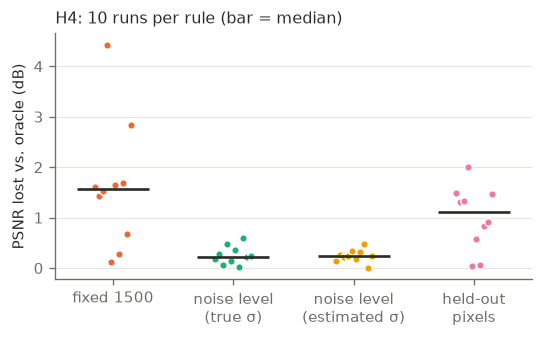

In [5]:
RULE_COLORS = dict(zip(RULES, PALETTE[1:5]))
SHORT = {"fixed (1500)": "fixed 1500", "noise level (true σ)": "noise level\n(true σ)",
         "noise level (estimated σ)": "noise level\n(estimated σ)", "held-out pixels": "held-out\npixels"}
fig, ax = plt.subplots(figsize=(4.6, 2.9))
for i, rule in enumerate(RULES):
    v = R.loc[R.rule == rule, "psnr_lost"].to_numpy()
    jitter = np.linspace(-0.15, 0.15, len(v))
    ax.scatter(i + jitter, v, s=20, color=RULE_COLORS[rule], edgecolor="white", linewidth=0.8, zorder=3)
    ax.hlines(np.median(v), i - 0.3, i + 0.3, color=INK, lw=1.6, zorder=4)
ax.set_xticks(range(len(RULES)), [SHORT[r] for r in RULES])
ax.set_ylabel("PSNR lost vs. oracle (dB)")
ax.grid(axis="x", visible=False)
ax.set_title("H4: 10 runs per rule (bar = median)", loc="left")
fig.tight_layout()
savefig(fig, "h4_psnr_lost")

**Example run** (`kodim03`, σ = 50) showing the signals each rule uses.
- **Left:** PSNR with the chosen stopping points.
- **Middle:** training MSE and the σ² line.
- **Right:** held-out loss vs. the true error on the whole image plus σ².

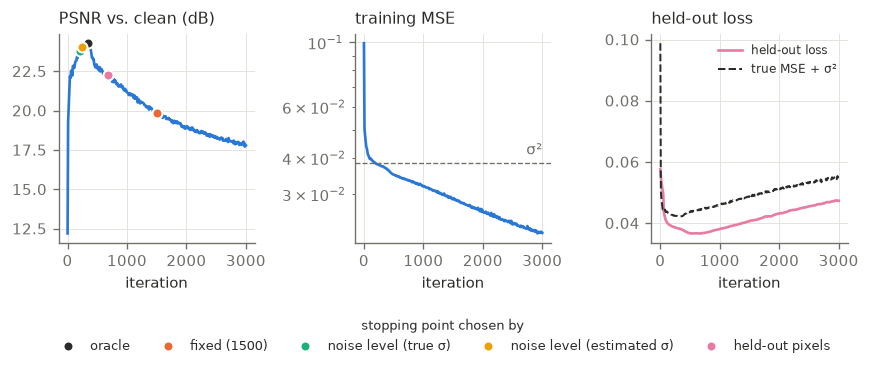

In [6]:
g = h1[(h1.image == "kodim03") & (h1.sigma == 50) & (h1.seed == 0)].reset_index(drop=True)
r = R[(R.image == "kodim03") & (R.sigma == 50) & (R.seed == 0)].set_index("rule")
s2 = (50 / 255) ** 2
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6), sharex=True)
ax = axes[0]
ax.plot(g["iter"], g["psnr_clean"], color=PALETTE[0])
for rule in ["oracle"] + RULES:
    it = r.loc[rule, "iter"]; p = r.loc[rule, "psnr"]
    c = INK if rule == "oracle" else RULE_COLORS[rule]
    ax.plot(it, p, "o", ms=6, color=c, mec="white", mew=1.2, label=rule, zorder=4)
ax.set_title("PSNR vs. clean (dB)", loc="left")
handles, labels = ax.get_legend_handles_labels()
ax = axes[1]
ax.plot(g["iter"], g["loss"], color=PALETTE[0])
ax.axhline(s2, color=MUTED, ls="--", lw=0.8)
ax.text(3000, s2 * 1.04, "σ²", color=MUTED, ha="right", va="bottom")
ax.set_yscale("log")
ax.set_title("training MSE", loc="left")
ax = axes[2]
true_mse = 10 ** (-g["psnr_clean"] / 10)
ax.plot(g["iter"], g["mse_holdout"].rolling(10, center=True, min_periods=1).mean(), color=RULE_COLORS["held-out pixels"], label="held-out loss")
ax.plot(g["iter"], true_mse + s2, color=INK, lw=1.2, ls="--", label="true MSE + σ²")
ax.set_title("held-out loss", loc="left")
ax.legend(fontsize=7)
for a in axes:
    a.set_xlabel("iteration")
fig.tight_layout()
fig.legend(handles, labels, loc="upper center", ncols=5, fontsize=7.5, bbox_to_anchor=(0.5, 0.0), title="stopping point chosen by", title_fontsize=7.5)
savefig(fig, "h4_example")

## Findings (H4)

**Noise-level rule (discrepancy principle): works very well.**
- Median loss of about 0.2 dB vs. the oracle, at most about 0.6 dB.
- Estimating σ from the noisy image is just as good: the estimates are within about 2 units of the true σ (on the 0–255 scale). In our setting the rule needs no extra information at all.

**Held-out pixels: works, but systematically stops too late.**
- About 1 dB lost on average, up to 2 dB.
- Reason: the identity *held-out loss = error on held-out pixels + σ²* holds, but the error *on the held-out pixels* is not the error on the whole image. The held-out pixels are never fitted directly; they are only inpainted from their neighbours. So noise reaches them later, and their error keeps falling after the full-image error has started to rise (right panel).

**Fixed budget: worst.**
- About 1.6 dB lost on average, up to 4.4 dB.
- The best iteration ranges from about 340 to 2000 depending on image and σ, so no single budget fits all.

**Answer to the second half of the research question:** yes. A stopping rule that uses only the noisy image (noise level with estimated σ) gets within about 0.25 dB of the oracle on these images.

## H5 — Does averaging outputs (EMA) make the stopping point matter less?

In [7]:
s_plain = summarize(h1, ["image", "sigma", "seed"])
ema = h1.assign(psnr_clean=h1["psnr_ema"], ssim_clean=h1["ssim_ema"])
s_ema = summarize(ema, ["image", "sigma", "seed"])
h5 = s_plain[["image", "sigma", "seed", "peak_psnr", "drop_psnr"]].merge(
    s_ema[["image", "sigma", "seed", "peak_psnr", "drop_psnr"]], on=["image", "sigma", "seed"], suffixes=("", "_ema"))
h5.loc["mean"] = h5[["peak_psnr", "drop_psnr", "peak_psnr_ema", "drop_psnr_ema"]].mean()
h5

,image,sigma,seed,peak_psnr,drop_psnr,peak_psnr_ema,drop_psnr_ema
0,kodim03,25.0,0.0,28.91,3.71,31.33,3.85
1,kodim03,25.0,1.0,28.81,3.39,31.16,3.37
2,kodim03,25.0,2.0,28.77,3.27,31.05,3.24
3,kodim03,50.0,0.0,24.28,6.49,26.82,7.45
4,kodim05,25.0,0.0,24.20,0.48,25.89,0.60
5,kodim05,50.0,0.0,20.52,3.06,22.34,3.51
6,kodim13,25.0,0.0,23.88,0.21,25.56,0.30
7,kodim13,50.0,0.0,20.86,3.49,22.44,3.55
8,kodim15,25.0,0.0,27.54,2.03,29.55,1.50
9,kodim15,50.0,0.0,23.52,4.85,25.77,5.34


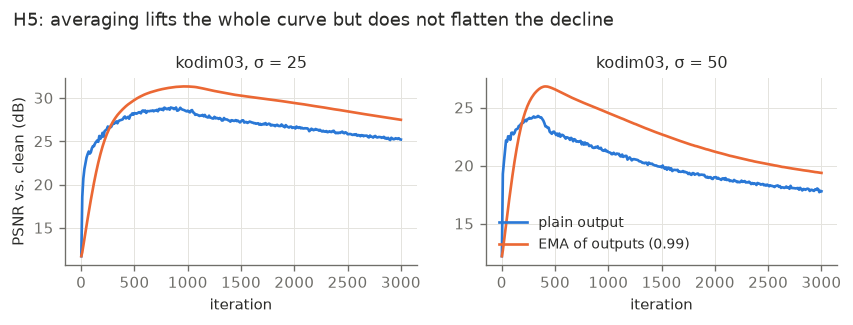

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), sharey=False)
for ax, sigma in zip(axes, (25, 50)):
    g = h1[(h1.image == "kodim03") & (h1.sigma == sigma) & (h1.seed == 0)]
    ax.plot(g["iter"], g["psnr_clean"], color=PALETTE[0], label="plain output")
    ax.plot(g["iter"], g["psnr_ema"], color=PALETTE[1], label="EMA of outputs (0.99)")
    ax.set_title(f"kodim03, σ = {sigma}")
    ax.set_xlabel("iteration")
axes[0].set_ylabel("PSNR vs. clean (dB)")
axes[1].legend(loc="lower left")
fig.suptitle("H5: averaging lifts the whole curve but does not flatten the decline", x=0.02, ha="left")
fig.tight_layout()
savefig(fig, "h5_ema")

## Findings (H5)

**H5 as stated is refuted, but averaging still helps a lot.**
- The drop after the peak is **not** smaller with EMA: 3.3 dB vs. 3.1 dB on average. So the stopping point matters just as much.
- But the EMA output is about **2 dB better at every point of the curve**: mean peak 27.2 vs. 25.1 dB, and the final value is also about 1.9 dB higher.
- A likely reason: every plain output is computed from a randomly perturbed input `z` (std 1/30), so it carries extra step-to-step jitter. Averaging about 100 consecutive outputs cancels that jitter, much like an ensemble.
- Practical consequence: stopping rules should be applied to the EMA output. Combined with the noise-level rule, this would give results about 2 dB above the plain oracle (not evaluated separately here).
- This is a simplification *inspired by* Cheng et al. (2019), who average SGLD posterior samples. It is not a reproduction of their method.